# 3. Sliced Wasserstein Distances, Mutual-Rank Affinity & Multi-Scale SNF

**What you will learn:**
1. How **Order-1 Sliced Wasserstein distance** ($\mathrm{SW}_1$) compares two extended persistence diagrams by projecting points (augmented with diagonal projections) onto 25 directions — and why order 1 preserves many small structures alongside the largest one.
2. What all **$5 \times 4 = 20$ distance matrices** reveal on `Top-1` (sorted by mission **for visualization only**).
3. Why **Mutual Ranks + Percentile Normalization** (`Obayashi & Kinoshita 2009`) neutralize arbitrary field scales without a single tuned weight.
4. How **Moment-Balanced Views** ($1/3\,\rho$, $1/3\,K$, $1/9\,(\varphi+\psi+J)$) fuse across the four scales via **Similarity Network Fusion (SNF)** diffusion $(k_{\mathrm{nn}}, t)$ to sharpen within-mission consensus.

In [1]:
import pickle, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import run_sweep as RS
from classification import fusion as F
L.style()

RES = ROOT / "results" / "epuck"
load = lambda p: pickle.load(open(p, "rb"))

## 1. Visual Geometry of Order-1 Sliced Wasserstein ($\mathrm{SW}_1$) & Pipeline Check

$$\mathrm{SW}_1(D, D') = \frac{1}{|\Theta|}\sum_{\theta\in\Theta}\sum_k \left|a^{\theta}_{(k)} - b^{\theta}_{(k)}\right|, \qquad d_{f,m}(A, B) = \sum_{s=1}^6 \mathrm{SW}_1\big(D^s_{f,m}(A), D^s_{f,m}(B)\big).$$

Let's visualize the 1D projection & diagonal augmentation on a tiny pair of 3-point diagrams, check convergence as the number of directions rises to `25`, and verify our 15-line `sw` matches the cached `dist_multiscale.pkl` to full precision!

Exact pipeline check: recomputed SW1 = 0.179962   |   stored = 0.179962


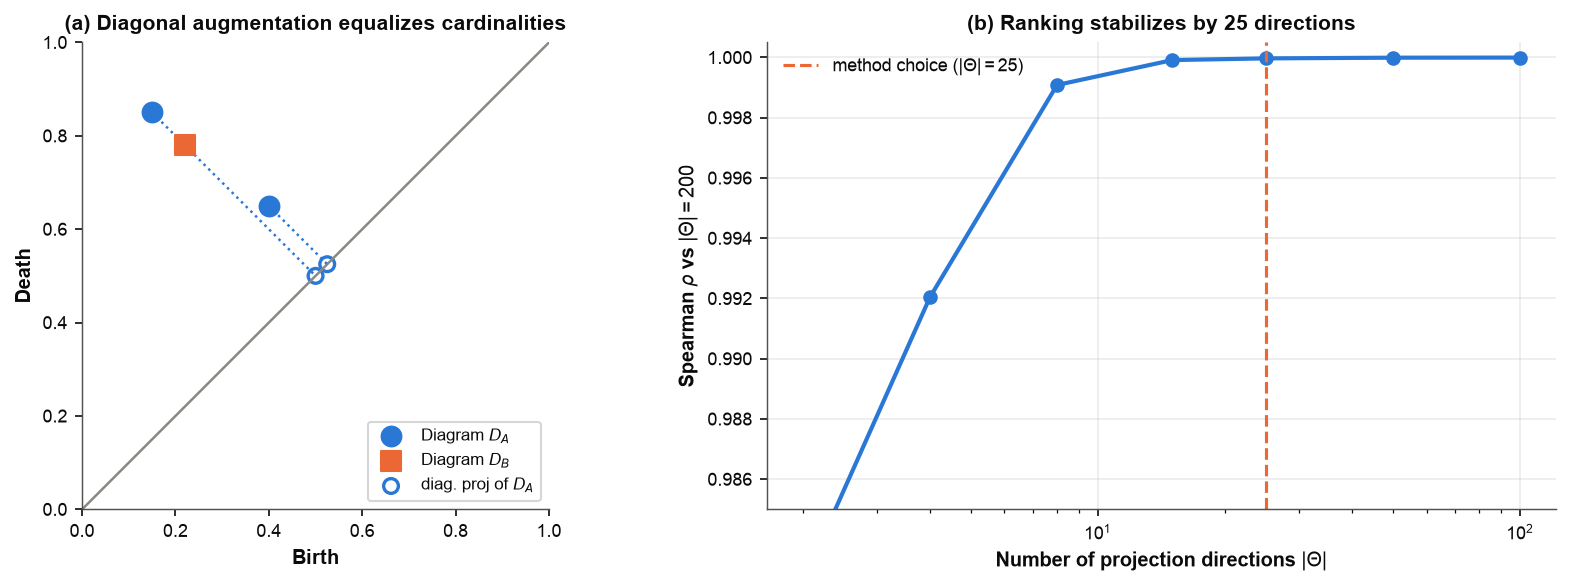

In [2]:
from scipy.stats import spearmanr

lab, rk, ctrl = RS.load_labels()
D, ladder = RS.load_distances()  # 20 matrices, 2500 x 2500

def sw(A, B, n_dirs=25):
    A = np.asarray(A, float).reshape(-1, 2); B = np.asarray(B, float).reshape(-1, 2)
    th = np.linspace(-np.pi / 2, np.pi / 2, n_dirs, endpoint=False)
    u = np.stack([np.cos(th), np.sin(th)], 1)
    dA = 0.5 * (A[:, 0] + A[:, 1]); dB = 0.5 * (B[:, 0] + B[:, 1])
    PA = np.concatenate([A @ u.T, dB[:, None] * (u[:, 0] + u[:, 1])[None, :]], 0)
    PB = np.concatenate([B @ u.T, dA[:, None] * (u[:, 0] + u[:, 1])[None, :]], 0)
    return float(np.abs(np.sort(PA, 0) - np.sort(PB, 0)).sum(0).mean())

# Check exact match on (run 0 vs run 1000, field rho, scale 3)
i, j, f, si = 0, 1000, "rho", 2
gi = lambda ti: load(RES / "stage2_alpha_dgms" / f"traj{ti:04d}_s{si}.pkl")["dgms"][f]
mine = sum(sw(a, b, 25) for a, b in zip(gi(i), gi(j)))
print(f"Exact pipeline check: recomputed SW1 = {mine:.6f}   |   stored = {D[f][si][i, j]:.6f}")

# Toy diagram + direction sensitivity plot
A_toy = np.array([[0.15, 0.85], [0.40, 0.65]])
B_toy = np.array([[0.22, 0.78]])
proj_A = np.repeat(0.5*(A_toy[:,0]+A_toy[:,1])[:,None], 2, 1)
proj_B = np.repeat(0.5*(B_toy[:,0]+B_toy[:,1])[:,None], 2, 1)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.2, 4.0))
ax0.plot([0, 1], [0, 1], color="#8a8984", lw=1.2)
ax0.scatter(A_toy[:,0], A_toy[:,1], s=90, c=L.MCOL[0], label="Diagram $D_A$", zorder=5)
ax0.scatter(B_toy[:,0], B_toy[:,1], s=90, marker="s", c=L.MCOL[1], label="Diagram $D_B$", zorder=5)
ax0.scatter(proj_A[:,0], proj_A[:,1], s=50, fc="none", ec=L.MCOL[0], lw=1.6, label="diag. proj of $D_A$")
for p, q in zip(A_toy, proj_A):
    ax0.plot([p[0], q[0]], [p[1], q[1]], ls=":", color=L.MCOL[0], lw=1.2)
ax0.set_xlim(0, 1); ax0.set_ylim(0, 1); ax0.set_aspect("equal")
ax0.set_title("(a) Diagonal augmentation equalizes cardinalities", fontweight="bold")
ax0.set_xlabel("Birth"); ax0.set_ylabel("Death"); ax0.legend(fontsize=8, loc="lower right")

# Convergence of SW1 vs 200 directions on 25 Top-1 runs
idx1 = RS.subset(1, rk)[::10]  # 25 representative runs across all 5 missions
dgms_sub = [load(RES / "stage2_alpha_dgms" / f"traj{int(ti):04d}_s2.pkl")["dgms"]["psi"] for ti in idx1]
def pdist_ndir(nd):
    m = len(dgms_sub); out = []
    for r in range(m):
        for c in range(r + 1, m):
            out.append(sum(sw(a, b, nd) for a, b in zip(dgms_sub[r], dgms_sub[c])))
    return np.array(out)

ref400 = pdist_ndir(200)
ns = [2, 4, 8, 15, 25, 50, 100]
rhos = [spearmanr(pdist_ndir(n), ref400).statistic for n in ns]
ax1.plot(ns, rhos, marker="o", lw=2.0, color=L.MCOL[0])
ax1.axvline(25, color=L.MCOL[1], ls="--", lw=1.5, label=r"method choice ($|\Theta|=25$)")
ax1.set_xscale("log"); ax1.set_ylim(0.985, 1.0005)
ax1.set_xlabel(r"Number of projection directions $|\Theta|$"); ax1.set_ylabel(r"Spearman $\rho$ vs $|\Theta|=200$")
ax1.set_title("(b) Ranking stabilizes by 25 directions", fontweight="bold")
ax1.legend(fontsize=8.5, frameon=False); ax1.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 2. All $5 \times 4 = 20$ Rank-Normalized Similarity Views on `Top-1`

Runs are ordered by mission (`50` per block: D-Gate, Foraging, Homing, Shelter, XOR) **for display only** — the pipeline is completely unsupervised. Notice how **every single field** captures some block structure while leaving partial ambiguity between at least two blocks (for example, `rho` sees Shelter vs XOR best, whereas `psi` separates D-Gate vs Foraging).

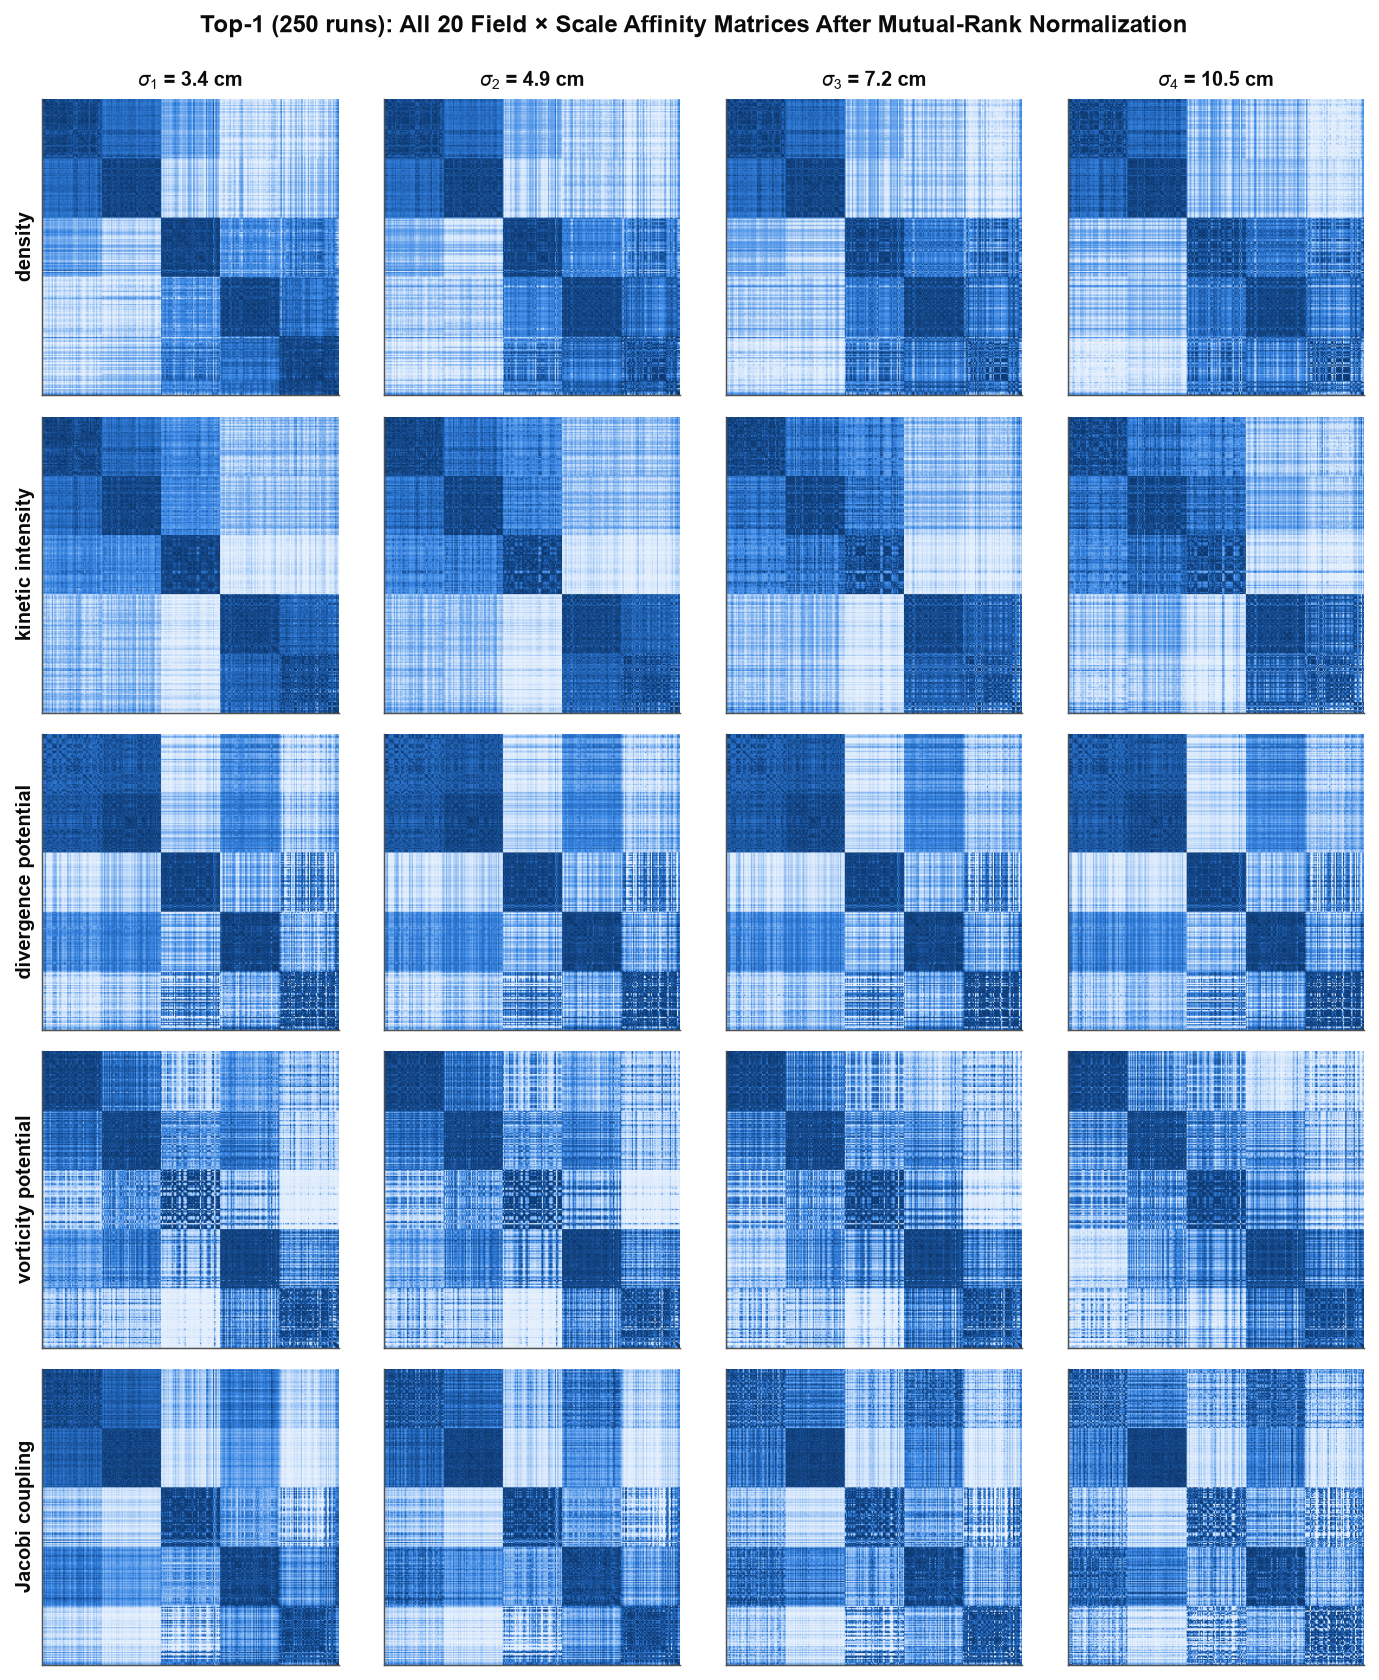

In [3]:
idx = RS.subset(1, rk)
Q = F.rank_normalise(D, F.ALL_FIELDS, idx)

fig, axes = plt.subplots(5, 4, figsize=(9.5, 11.2))
for a, f in enumerate(F.ALL_FIELDS):
    for b, s in enumerate(Q[f]):
        axes[a, b].imshow(1 - Q[f][s], cmap=L.SEQ, vmin=0, vmax=1)
        axes[a, b].set_xticks([]); axes[a, b].set_yticks([])
        if b == 0:
            axes[a, b].set_ylabel(L.FNAME[f], fontsize=9.5, fontweight="bold")
        if a == 0:
            axes[a, b].set_title(rf"$\sigma_{b+1}$ = {100*ladder[b]:.1f} cm", fontsize=9.5, fontweight="bold")
fig.suptitle("Top-1 (250 runs): All 20 Field × Scale Affinity Matrices After Mutual-Rank Normalization", fontsize=11.5, fontweight="bold", y=0.995)
plt.tight_layout(); plt.show()

## 3. Why Mutual Ranks + Percentile Ranks?

Raw $\mathrm{SW}_1$ distances live on incompatible dynamic ranges across $\rho_\sigma, K_\sigma, \varphi_\sigma, \psi_\sigma, J_\sigma$ and scales $\sigma_1\dots\sigma_4$. Transforming each matrix by **mutual rank** $\sqrt{r(A \to B)\, r(B \to A)}$ (`Obayashi & Kinoshita 2009`) and then **percentile rank** maps every matrix onto the identical Uniform$(0, 1]$ distribution so no field dominates by numerical amplitude.

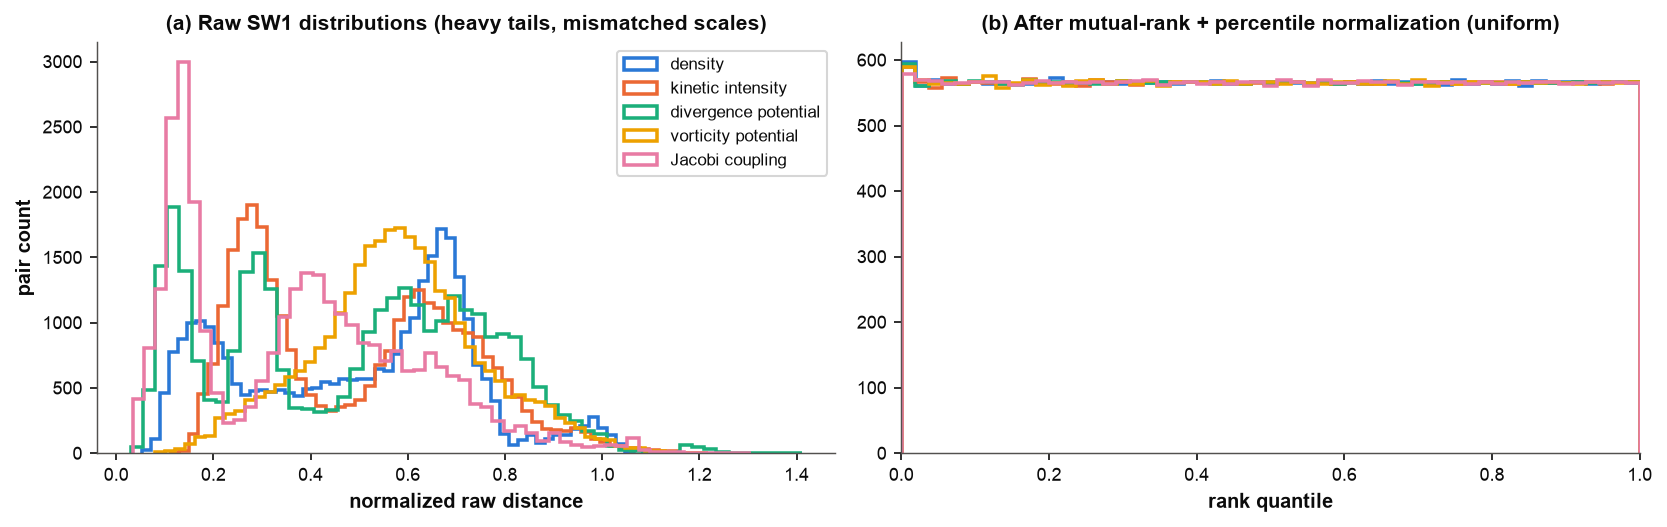

In [4]:
iu = np.triu_indices(len(idx), 1)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.6))
for c_i, f in enumerate(F.ALL_FIELDS):
    raw = np.asarray(D[f][2], float)[np.ix_(idx, idx)][iu]
    axes[0].hist(raw / np.quantile(raw, 0.99), bins=55, histtype="step", lw=1.7, color=L.MCOL[c_i], label=L.FNAME[f])
    axes[1].hist(Q[f][2][iu], bins=55, histtype="step", lw=1.7, color=L.MCOL[c_i], label=L.FNAME[f])
axes[0].set_title("(a) Raw SW1 distributions (heavy tails, mismatched scales)", fontweight="bold")
axes[1].set_title("(b) After mutual-rank + percentile normalization (uniform)", fontweight="bold")
axes[0].set_xlabel("normalized raw distance"); axes[1].set_xlabel("rank quantile")
axes[0].set_ylabel("pair count"); axes[0].legend(fontsize=8); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

## 4. Moment-Balanced Views $W_m$ & Multi-Scale SNF Diffusion

Equal weight per moment ($1/3$ density, $1/3$ kinetic intensity, $1/9$ each for $\varphi_\sigma, \psi_\sigma, J_\sigma$) constructs four views $W_1\dots W_4$, which **Similarity Network Fusion (SNF)** diffuses across scales: links supported at multiple spatial widths reinforce into sharp block diagonals!

Weights per field: {'rho': 0.3333333333333333, 'K': 0.3333333333333333, 'phi': 0.1111111111111111, 'psi': 0.1111111111111111, 'J': 0.1111111111111111}


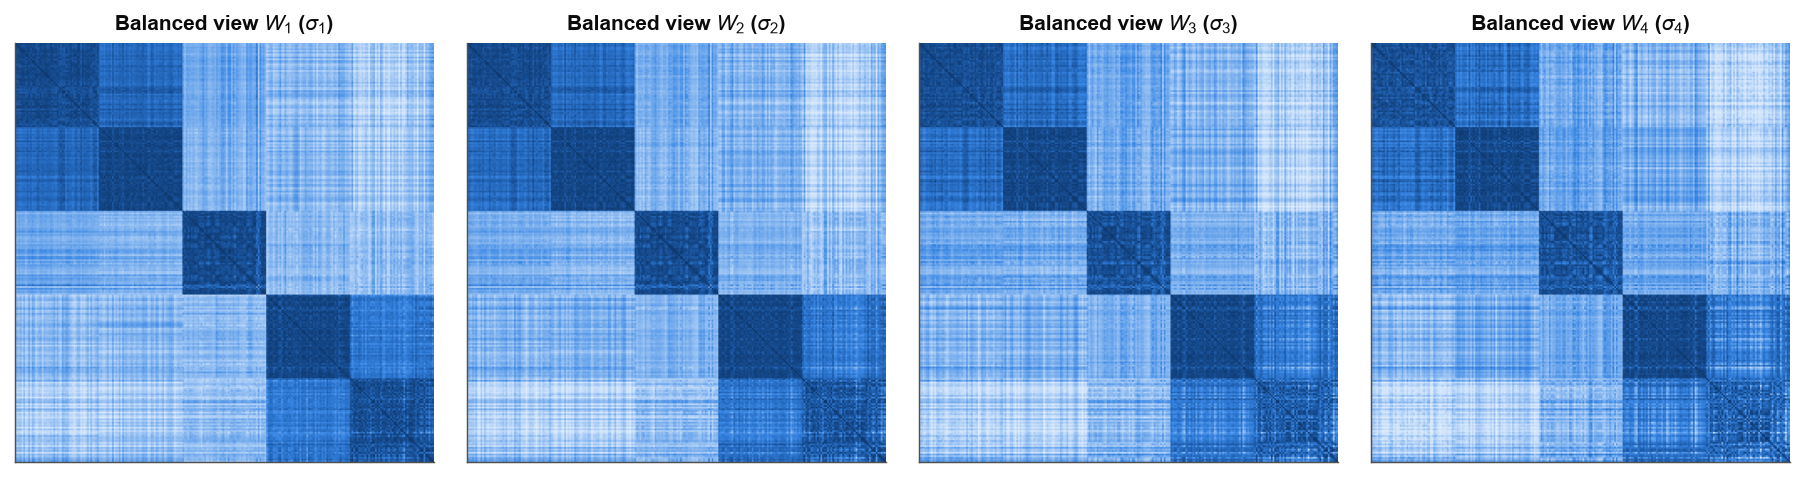

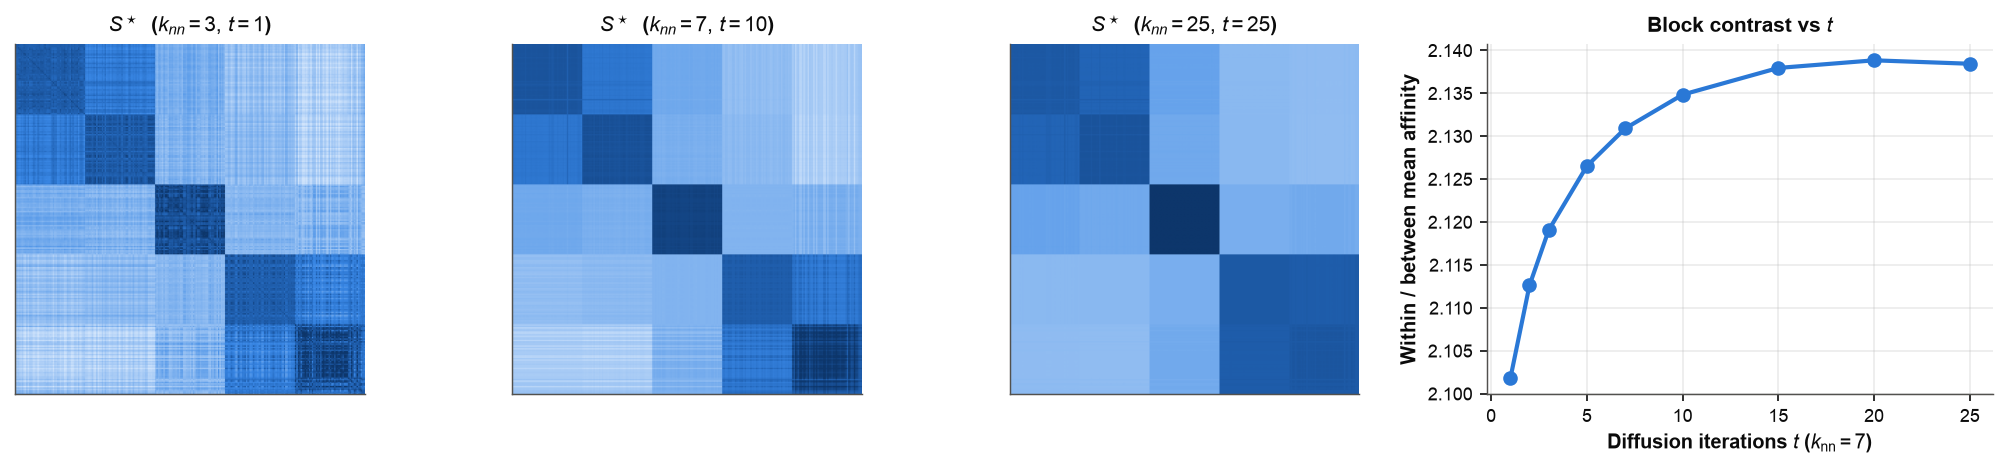

In [5]:
print("Weights per field:", F.source_weights(F.ALL_FIELDS))
views = F.scale_views(Q)

fig, axes = plt.subplots(1, 4, figsize=(12.2, 3.1))
for k, v in enumerate(views):
    axes[k].imshow(v, cmap=L.SEQ, vmin=0, vmax=1)
    axes[k].set_title(rf"Balanced view $W_{k+1}$ ($\sigma_{k+1}$)", fontsize=10, fontweight="bold")
    axes[k].set_xticks([]); axes[k].set_yticks([])
plt.tight_layout(); plt.show()

y1 = lab[idx]
same_mask = (y1[:, None] == y1[None, :]) & ~np.eye(len(y1), dtype=bool)
diff_mask = y1[:, None] != y1[None, :]

fig, axes = plt.subplots(1, 4, figsize=(13.6, 3.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.3]})
for ax, (k, t) in zip(axes[:3], [(3, 1), (7, 10), (25, 25)]):
    S = F.consensus(views, k, t)
    ax.imshow(S, cmap=L.SEQ, vmin=0, vmax=np.quantile(S, 0.992))
    ax.set_title(rf"$S^\star$  ($k_{{nn}}={k},\, t={t}$)", fontsize=10, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

ts = [1, 2, 3, 5, 7, 10, 15, 20, 25]
gaps_7 = []
for t in ts:
    S = F.consensus(views, 7, t)
    gaps_7.append(S[same_mask].mean() / max(S[diff_mask].mean(), 1e-9))
axes[3].plot(ts, gaps_7, marker="o", lw=2.0, color=L.MCOL[0])
axes[3].set_xlabel(r"Diffusion iterations $t$ ($k_{\mathrm{nn}}=7$)")
axes[3].set_ylabel("Within / between mean affinity")
axes[3].set_title("Block contrast vs $t$", fontsize=10, fontweight="bold")
axes[3].grid(alpha=0.25)
plt.tight_layout(); plt.show()